# Image Retrieval System

A content-based image retrieval (CBIR) pipeline built to compare classical and learned approaches to finding visually similar images. The system indexes a database of images and, given a query image, retrieves the closest matches — using several different feature representations and matching strategies:

- **SIFT** keypoint descriptors, visualized and compared for scale/rotation invariance
- **CNN features** from a pre-trained VGG16 (both the last conv layer and the final FC layer)
- Cosine similarity and Euclidean distance implemented from scratch
- A full **bag-of-visual-words** pipeline: SIFT → k-means codebook → inverted index
- A **vector database** (Pinecone) storing CNN embeddings for scalable nearest-neighbor search
- Quantitative evaluation with mean Average Precision (mAP) and precision-recall curves, plus a look at failure cases

Dataset: [Imagenette](https://github.com/fastai/imagenette), a 10-class subset of ImageNet.

## Setup

In [58]:
# Download the Imagenette dataset
!curl -L https://s3.amazonaws.com/fast-ai-imageclas/imagenette2-160.tgz --output imagenette2-160.tgz
!tar -xzf imagenette2-160.tgz

  % Total    % Received % Xferd  Average Speed  Time    Time    Time   Current
                                 Dload  Upload  Total   Spent   Left   Speed

  0      0   0      0   0      0      0      0                              0
  7 94.41M   7  6.98M   0      0  6.96M      0   00:13   00:01   00:12  6.97M
 22 94.41M  22 21.27M   0      0 10.62M      0   00:08   00:02   00:06 10.63M
 37 94.41M  37 35.33M   0      0 11.77M      0   00:08   00:03   00:05 11.78M
 50 94.41M  50 47.49M   0      0 11.86M      0   00:07   00:04   00:03 11.87M
 63 94.41M  63 60.05M   0      0 12.00M      0   00:07   00:05   00:02 12.01M
 78 94.41M  78 74.17M   0      0 12.36M      0   00:07   00:06   00:01 13.44M
 93 94.41M  93 88.49M   0      0 12.63M      0   00:07   00:07         13.44M
100 94.41M 100 94.41M   0      0 12.73M      0   00:07   00:07         13.44M
100 94.41M 100 94.41M   0      0 12.73M      0   00:07   00:07         13.44M
100 94.41M 100 94.41M   0      0 12.73M      0   00:07   00:07 

In [59]:
%pip install -q \
  torch \
  torchvision \
  opencv-python \
  scikit-learn \
  matplotlib \
  pinecone-client==3.1.0

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Users\nafis\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


In [60]:
import torch
import torch.nn as nn
from torchvision import datasets, models, transforms
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from collections import defaultdict

%matplotlib inline

In [61]:
# Configure root folder
data_dir = 'imagenette2-160'

# Human-readable names for the classes
imagenette_labels = {'n01440764': 'tench', 'n02102040': 'English springer', 'n02979186': 'cassette player', 'n03000684': 'chain saw',
    'n03028079': 'church', 'n03394916': 'French horn', 'n03417042': 'garbage truck', 'n03425413': 'gas pump',
    'n03445777': 'golf ball', 'n03888257': 'parachute'}

# Basic preprocessing
preprocess = transforms.Compose([
    transforms.Resize(160),
    transforms.CenterCrop(160),
    transforms.ToTensor(),
])

# Load the train folder and the val folder
train_full = datasets.ImageFolder(os.path.join(data_dir, 'train'), transform=preprocess)
val_full = datasets.ImageFolder(os.path.join(data_dir, 'val'), transform=preprocess)

class_names = [imagenette_labels[c] for c in train_full.classes]
print("Classes:", class_names)
print("Total train images:", len(train_full), " Total val images:", len(val_full))

Classes: ['tench', 'English springer', 'cassette player', 'chain saw', 'church', 'French horn', 'garbage truck', 'gas pump', 'golf ball', 'parachute']
Total train images: 9469  Total val images: 3925


In [62]:
# Use a subset of the dataset
# database = 50 images/class = 500 images
# queries = 10 images/class = 100 queries
def subset_per_class(dataset, n_per_class):
    counts, idxs = {}, []
    for i, (_, label) in enumerate(dataset.imgs):
        if counts.get(label, 0)<n_per_class:
            idxs.append(i)
            counts[label] = counts.get(label, 0)+1
    return idxs

db_idx = subset_per_class(train_full, 50)
query_idx = subset_per_class(val_full, 10)

db_dataset = torch.utils.data.Subset(train_full, db_idx)
query_dataset = torch.utils.data.Subset(val_full, query_idx)

# The corresponding (path, label) lists
db_imgs = [train_full.imgs[i] for i in db_idx]
query_imgs = [val_full.imgs[i] for i in query_idx]

print("Database (train) images:", len(db_dataset))
print("Query (test) images:", len(query_dataset))

Database (train) images: 500
Query (test) images: 100


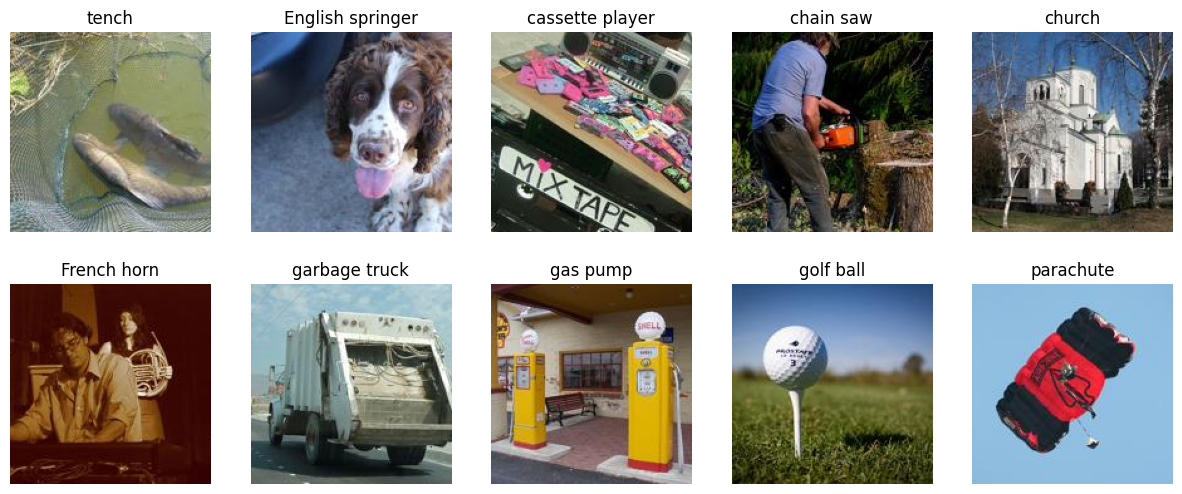

In [63]:
# Indices of the sample images
sample_idx = list(range(0, len(db_dataset), len(db_dataset)//10))

# Display sample images and their labels
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for ax, i in zip(axes.ravel(), sample_idx):
    img, label = db_dataset[i]
    ax.imshow(img.permute(1, 2, 0).numpy())
    ax.set_title(class_names[label])
    ax.axis('off')
plt.show()

**Pre-processing:** each image's shorter side is resized to 160px, then center-cropped to 160×160, so every image has the same size. Images are then converted to tensors with `ToTensor()`. Further preprocessing happens later, since the two feature extractors need different inputs: SIFT works on the raw image, while the CNN needs ImageNet normalization, so each applies its own preprocessing step.

## Feature Extraction

#### 1. SIFT Feature Extraction

In [64]:
# Use OpenCV's SIFT to extract keypoints and descriptors for sample images
sample_paths = [db_imgs[i][0] for i in sample_idx[:5]]

sift = cv2.SIFT_create()
for path in sample_paths:
    img = cv2.imread(path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    keypoints, descriptors = sift.detectAndCompute(gray, None)
    print(os.path.basename(path), "- keypoints:", len(keypoints), " descriptors:", descriptors.shape)

ILSVRC2012_val_00000293.JPEG - keypoints: 169  descriptors: (169, 128)
ILSVRC2012_val_00000665.JPEG - keypoints: 305  descriptors: (305, 128)
ILSVRC2012_val_00000557.JPEG - keypoints: 357  descriptors: (357, 128)
ILSVRC2012_val_00000537.JPEG - keypoints: 398  descriptors: (398, 128)
ILSVRC2012_val_00004939.JPEG - keypoints: 305  descriptors: (305, 128)


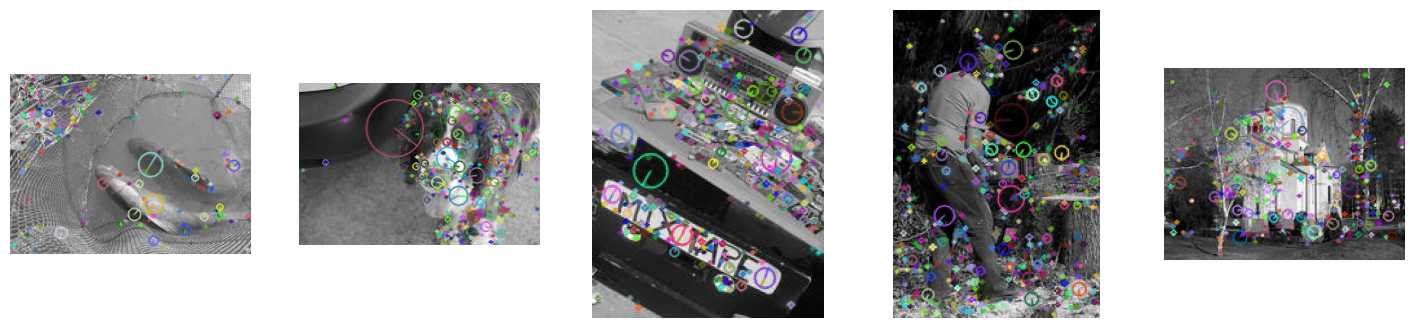

In [65]:
# Visualize the detected SIFT keypoints on the sample images
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, path in zip(axes, sample_paths):
    img = cv2.imread(path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    keypoints = sift.detect(gray, None)
    out = cv2.drawKeypoints(gray, keypoints, img, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    ax.imshow(cv2.cvtColor(out, cv2.COLOR_BGR2RGB))
    ax.axis('off')
plt.show()

SIFT achieves scale invariance by building a scale space: it progressively blurs the image with Gaussians and takes Differences of Gaussians (DoG), then detects keypoints as the local maxima and minima across both the image space and the scale space, where each candidate point is compared against its 26 neighbours (8 in the same scale and 9 in each of the scales above and below). Therefore a feature that is detected on a small image is matched with the corresponding feature on a larger image.

SIFT achieves rotation invariance through orientation assignment: for each keypoint it computes the gradient magnitudes and directions of the pixels in a local window, builds a 36-bin histogram, and takes the peak as a canonical orientation. The descriptor is then measured relative to that orientation, so rotating the image does not change the descriptor.

#### 2. CNN Feature Extraction

In [66]:
# CNN feature extraction with VGG16
from PIL import Image as PIL_Image

weights = models.VGG16_Weights.DEFAULT
vgg = models.vgg16(weights=weights)
vgg.eval()
vgg_transforms = weights.transforms()

# Extract from the last conv layer and the final FC layer for the sample images
for path in sample_paths:
    img = PIL_Image.open(path).convert('RGB')
    x = vgg_transforms(img).unsqueeze(0)
    with torch.no_grad():
        conv_feat = vgg.features(x)
        fc_feat = vgg(x)
    print(os.path.basename(path), "- conv:", tuple(conv_feat.shape), " fc:", tuple(fc_feat.shape))

ILSVRC2012_val_00000293.JPEG - conv: (1, 512, 7, 7)  fc: (1, 1000)
ILSVRC2012_val_00000665.JPEG - conv: (1, 512, 7, 7)  fc: (1, 1000)
ILSVRC2012_val_00000557.JPEG - conv: (1, 512, 7, 7)  fc: (1, 1000)
ILSVRC2012_val_00000537.JPEG - conv: (1, 512, 7, 7)  fc: (1, 1000)
ILSVRC2012_val_00004939.JPEG - conv: (1, 512, 7, 7)  fc: (1, 1000)


The last convolutional layer produces a feature map of shape (512, 7, 7), which is 25088 values in a 7x7 spatial grid of 512-channel features. The final fully connected layer produces a single 1000-dimensional vector with no spatial structure left. The convolutional features therefore keep spatial information and capture patterns such as edges, textures, and object parts, while the fully connected features are high-level and semantic that describe what the image is.

For retrieval, the fully connected layer's features are more suitable, because they are more compact and semantic, so two images of the same category get similar vectors even if they differ pixel by pixel, whereas the convolutional layer map represents more low-level features.

## Similarity Measures

In [67]:
# Generate embeddings for every database image
class FeatureExtractor(nn.Module):
    def __init__(self):
        super().__init__()
        weights = models.VGG16_Weights.DEFAULT
        self.features = models.vgg16(weights=weights).features
        self.transforms = weights.transforms()
        self.features.eval()

    def forward(self, x):
        with torch.no_grad():
            x = self.transforms(x)
            x = self.features(x)
            x = x.mean(dim=[2, 3])
            return x

extractor = FeatureExtractor()

# Extract a feature vector for every database image
db_loader = torch.utils.data.DataLoader(db_dataset, batch_size=32, shuffle=False)
db_features, db_labels = [], []
for images, labels in db_loader:
    db_features.append(extractor(images).numpy())
    db_labels += labels.tolist()

db_features = np.vstack(db_features)
db_labels = np.array(db_labels)
print("Database features:", db_features.shape)

Database features: (500, 512)


In [68]:
# Cosine similarity and Euclidean distance implemented from scratch
def cosine_similarity(a, b):
    return np.dot(a, b)/(np.linalg.norm(a)*np.linalg.norm(b))

def euclidean_distance(a, b):
    return np.sqrt(np.sum((a-b)**2))

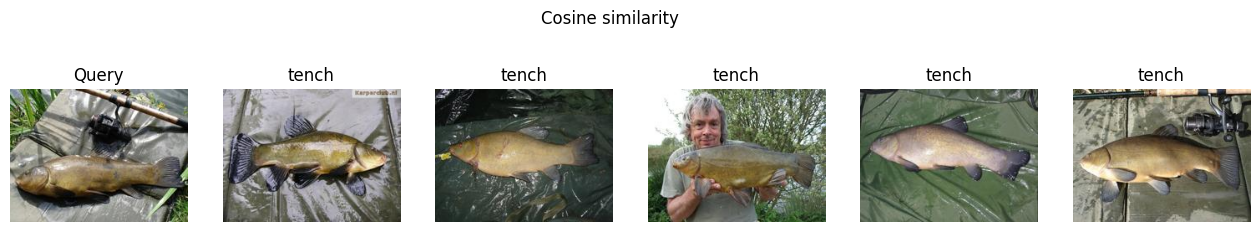

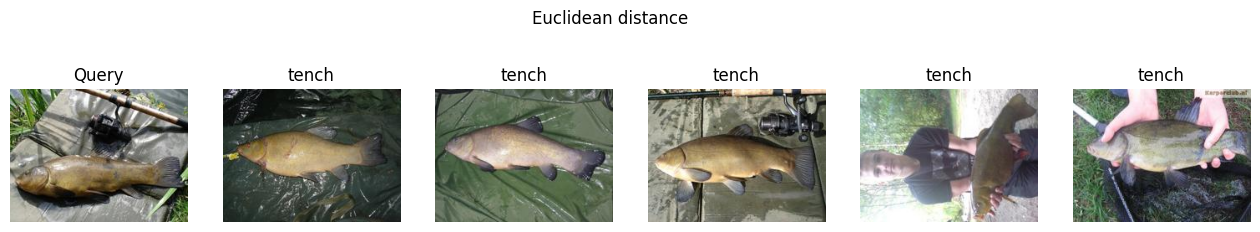

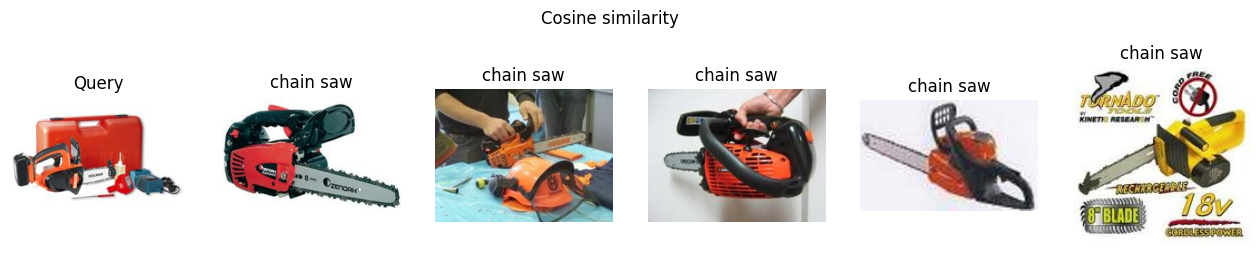

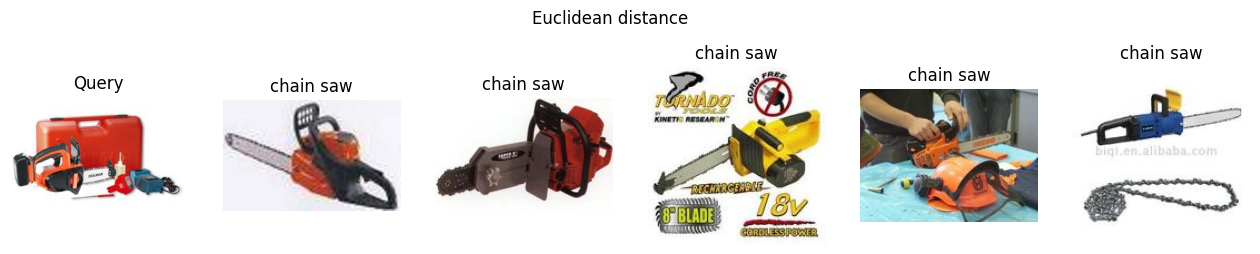

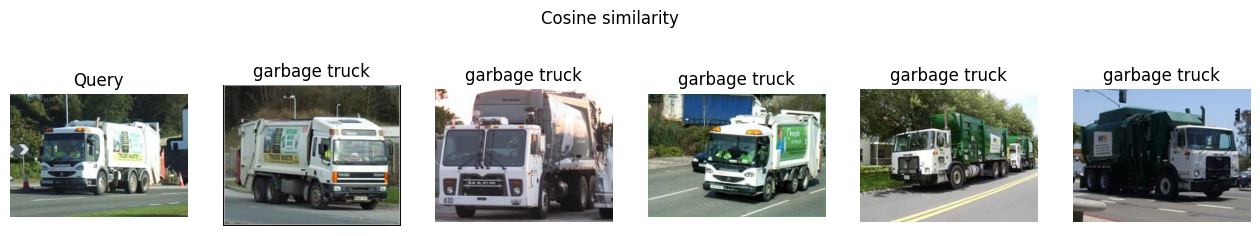

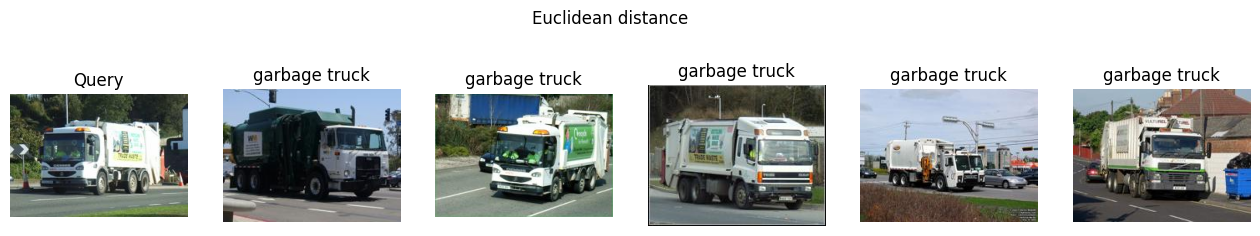

In [69]:
# A simple search system that returns the top-K most similar database images
def retrieve(query_feat, db_features, metric, k=5):
    if metric=='cosine':
        scores = [cosine_similarity(query_feat, f) for f in db_features]
        order = np.argsort(scores)[::-1]
    else:
        scores = [euclidean_distance(query_feat, f) for f in db_features]
        order = np.argsort(scores)
    return order[:k]

def show_results(qpath, db_indices, title):
    fig, axes = plt.subplots(1, len(db_indices)+1, figsize=(16, 3))
    axes[0].imshow(PIL_Image.open(qpath).convert('RGB'))
    axes[0].set_title("Query")
    axes[0].axis('off')
    for ax, di in zip(axes[1:], db_indices):
        path, label = db_imgs[di]
        ax.imshow(PIL_Image.open(path).convert('RGB'))
        ax.set_title(class_names[label])
        ax.axis('off')
    fig.suptitle(title)
    plt.show()

query_sample_paths = [query_imgs[i][0] for i in range(0, len(query_imgs), len(query_imgs)//3)][:3]

for qpath in query_sample_paths:
    qimg  = preprocess(PIL_Image.open(qpath).convert('RGB')).unsqueeze(0)
    qfeat = extractor(qimg).numpy()[0]
    show_results(qpath, retrieve(qfeat, db_features, 'cosine', 5), "Cosine similarity")
    show_results(qpath, retrieve(qfeat, db_features, 'euclidean', 5), "Euclidean distance")

According to the results above, the two metrics return broadly similar top-K images. This is because the CNN embeddings have similar magnitudes, so ranking by angle (cosine) and by straight-line distance (Euclidean) gives a similar order. The main difference is that cosine only compares the direction of the vectors and ignores their length, while Euclidean is also affected by magnitude, so it can sometimes rank a less relevant image higher, and therefore cosine is usually the more reliable choice.

## Bag-of-Visual-Words Retrieval Pipeline

In [70]:
import numpy as np
import cv2
from sklearn.cluster import KMeans

def extract_sift_features(image):
    # Convert the image to grayscale
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    
    # Create a SIFT feature extractor
    sift = cv2.SIFT_create()
    
    # Detect and compute SIFT features
    keypoints, descriptors = sift.detectAndCompute(gray, None)

    return descriptors

def cluster_features(features, k):
    # Perform K-means clustering
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(features)
    
    # Get the cluster centers (visual words)
    visual_words = kmeans.cluster_centers_
    
    return visual_words

In [71]:
# Extract SIFT features from each database image and create an image patch codebook
db_descriptors = []
for path, label in db_imgs:
    image = cv2.imread(path)
    desc = extract_sift_features(image)
    if desc is None:
        desc = np.zeros((0, 128), dtype=np.float32)
    db_descriptors.append(desc)

all_descriptors = np.vstack(db_descriptors)
k = 300
visual_words = cluster_features(all_descriptors, k)

In [72]:
# Assign each descriptor to its nearest visual word
def assign_visual_words(descriptors, visual_words):
    ids = []
    for d in descriptors:
        distances = np.linalg.norm(visual_words-d, axis=1)
        ids.append(int(np.argmin(distances)))
    return ids

db_visual_words = [assign_visual_words(d, visual_words) for d in db_descriptors]

In [73]:
# Inverted index
def map_function(img_id, words):
    return [(w, img_id) for w in set(words)]

def reduce_function(word, img_ids):
    return (word, sorted(img_ids))

def create_inverted_index(db_visual_words):
    mapped = []
    for img_id, words in enumerate(db_visual_words):
        mapped.extend(map_function(img_id, words))

    grouped = defaultdict(list)
    for word, img_id in mapped:
        grouped[word].append(img_id)

    inverted_index = {}
    for word, img_ids in grouped.items():
        _, postings = reduce_function(word, img_ids)
        inverted_index[word] = postings
    return inverted_index

inverted_index = create_inverted_index(db_visual_words)

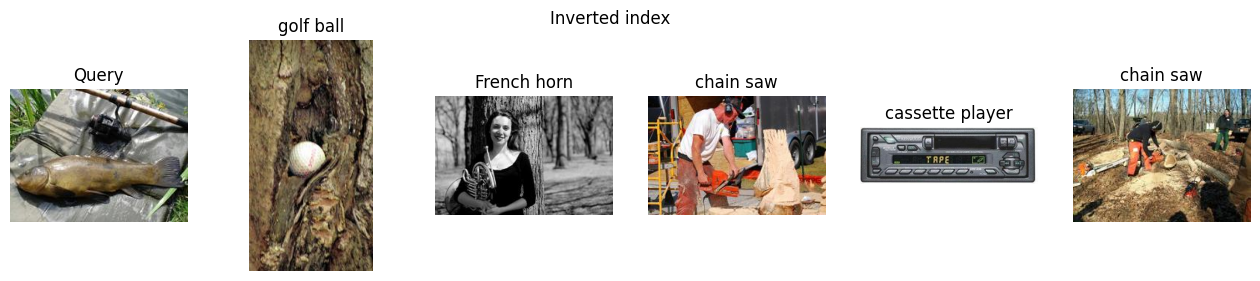

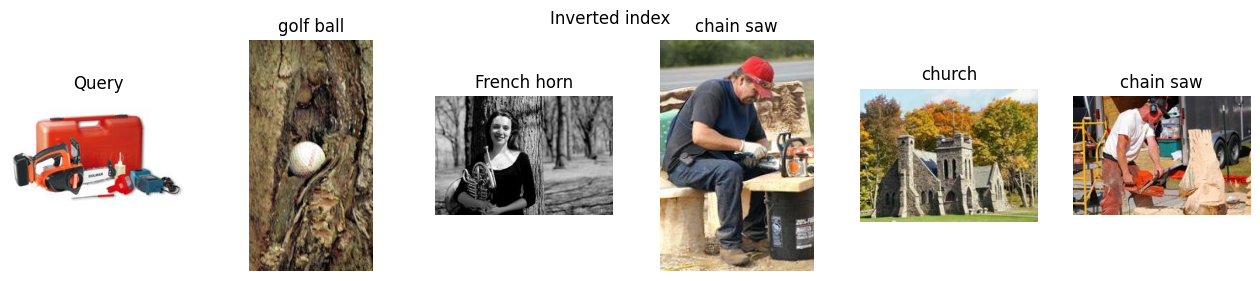

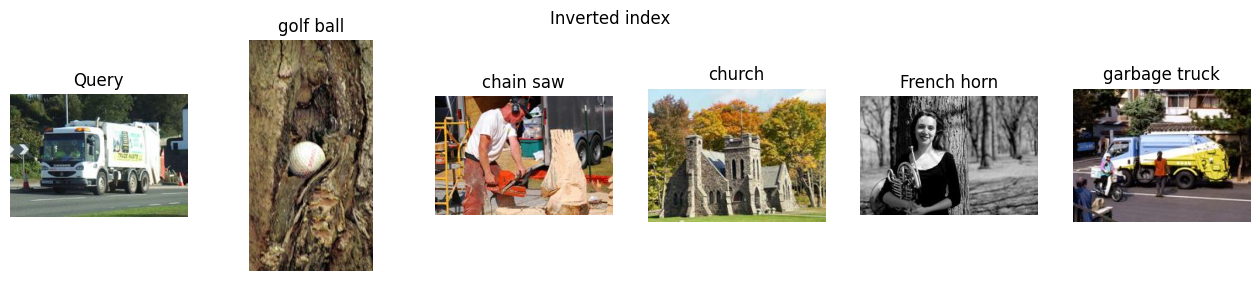

In [74]:
# Extract SIFT from a query image and assign its features to visual words
# Use the inverted index to retrieve database images and rank them by the term frequency, then display the top-K
def retrieve_bovw(query_path, k=5):
    image = cv2.imread(query_path)
    desc = extract_sift_features(image)
    query_words = set(assign_visual_words(desc, visual_words))

    scores = {}
    for w in query_words:
        for img_id in inverted_index.get(w, []):
            scores[img_id] = scores.get(img_id, 0)+1

    ranked = sorted(scores, key=scores.get, reverse=True)[:k]
    return ranked

for qpath in query_sample_paths:
    results = retrieve_bovw(qpath, 5)
    show_results(qpath, results, "Inverted index")

## Vector Database Integration (Pinecone)

In [ ]:
# Connect to Pinecone and create an empty index
from pinecone import Pinecone, ServerlessSpec
import time, os
from dotenv import load_dotenv

load_dotenv()
api_key = os.environ["PINECONE_API_KEY"]  # set this in a local .env file, see .env.example
pc = Pinecone(api_key=api_key)

index_name = "image-retrieval-cbir"
spec = ServerlessSpec(cloud='aws', region='us-east-1')

if index_name not in [ix["name"] for ix in pc.list_indexes()]:
    pc.create_index(index_name, dimension=512, metric='cosine', spec=spec)
    while not pc.describe_index(index_name).status['ready']:
        time.sleep(1)

index = pc.Index(index_name)
time.sleep(1)
print(index.describe_index_stats())

In [76]:
# Insert the CNN feature vectors of the database images into Pinecone
vectors = []
for i in range(len(db_features)):
    path, label = db_imgs[i]
    vectors.append({
        "id": str(i),
        "values": db_features[i].tolist(),
        "metadata": {"label": int(label), "image_url": path}
    })

index.upsert(vectors)
time.sleep(1)
print(index.describe_index_stats())

{'dimension': 512,
 'index_fullness': 0.0,
 'namespaces': {'': {'vector_count': 500}},
 'total_vector_count': 500}


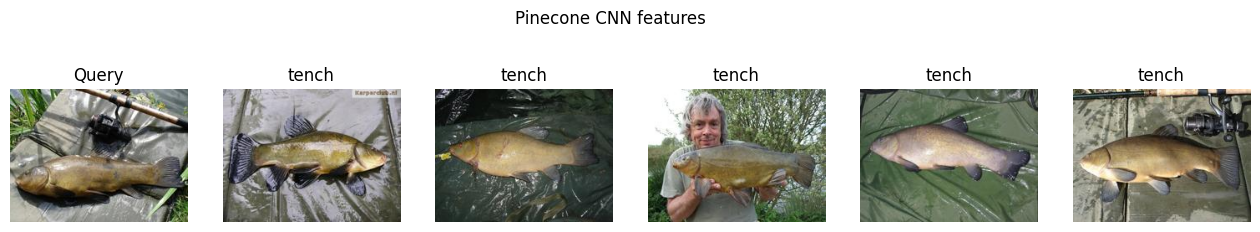

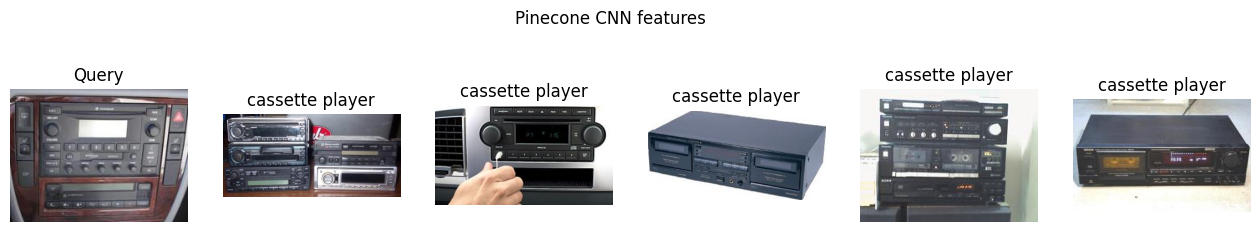

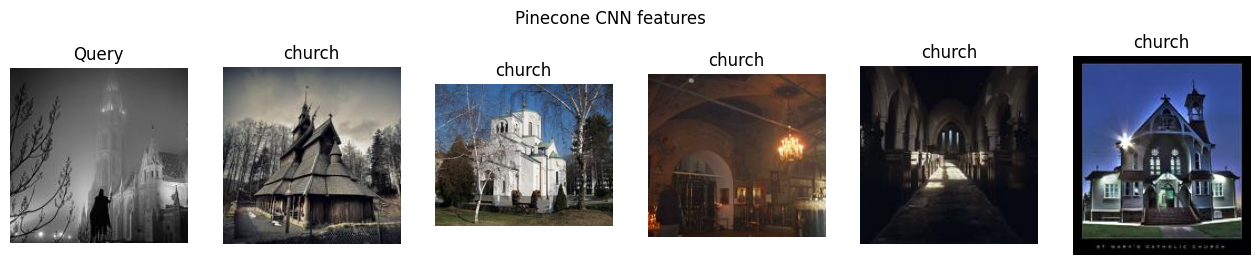

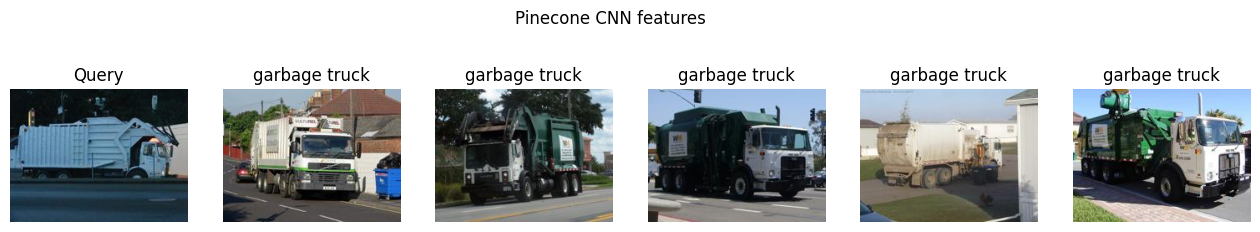

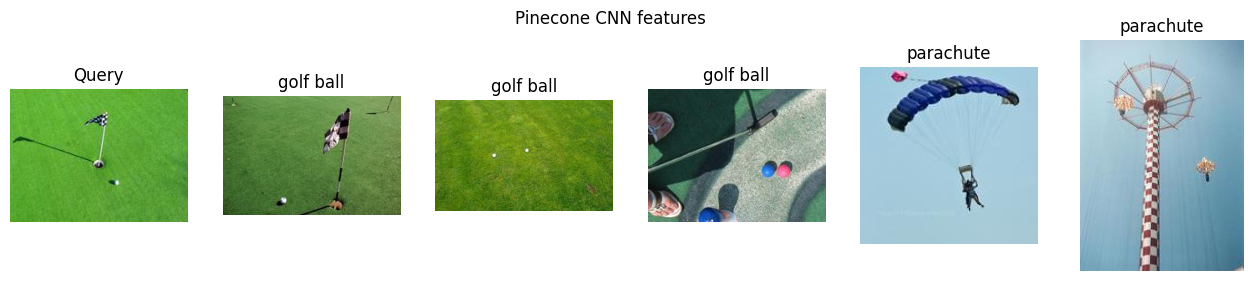

In [77]:
# Query the vector database with 5 sample images and show the results
def pinecone_search(query_path, k=5):
    qimg = preprocess(PIL_Image.open(query_path).convert('RGB')).unsqueeze(0)
    qfeat = extractor(qimg).numpy()[0].tolist()
    res = index.query(vector=qfeat, top_k=k, include_metadata=True)
    return [int(m['id']) for m in res['matches']]

query5 = [query_imgs[i][0] for i in range(0, len(query_imgs), len(query_imgs)//5)][:5]
for qpath in query5:
    show_results(qpath, pinecone_search(qpath, 5), "Pinecone CNN features")

mAP CNN embeddings (cosine): 0.733
mAP SIFT bag-of-visual-words: 0.128


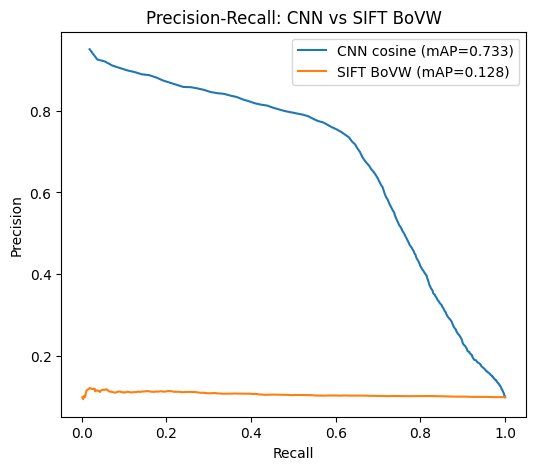

In [78]:
# Evaluate retrieval with mAP and create precision-recall curves
def rank_cnn(qpath):
    qimg = preprocess(PIL_Image.open(qpath).convert('RGB')).unsqueeze(0)
    qfeat = extractor(qimg).numpy()[0]
    scores = [cosine_similarity(qfeat, f) for f in db_features]
    return np.argsort(scores)[::-1]

def rank_bovw(qpath):
    desc = extract_sift_features(cv2.imread(qpath))
    qwords = set(assign_visual_words(desc, visual_words)) if desc is not None else set()
    scores = np.zeros(len(db_imgs))
    for w in qwords:
        for img_id in inverted_index.get(w, []):
            scores[img_id] += 1
    return np.argsort(scores)[::-1]

def evaluate(rank_fn):
    aps, P, R = [], np.zeros(len(db_imgs)), np.zeros(len(db_imgs))
    for qpath, qlabel in query_imgs:
        order = rank_fn(qpath)
        rel = (db_labels[order]==qlabel).astype(int)
        cum = np.cumsum(rel)
        ranks = np.arange(1, len(rel)+1)
        precision, recall = cum/ranks, cum/rel.sum()
        aps.append((precision*rel).sum()/rel.sum())
        P += precision
        R += recall
    n = len(query_imgs)
    return np.mean(aps), P/n, R/n

map_cnn, P_cnn, R_cnn = evaluate(rank_cnn)
map_bovw, P_bovw, R_bovw = evaluate(rank_bovw)
print(f"mAP CNN embeddings (cosine): {map_cnn:.3f}")
print(f"mAP SIFT bag-of-visual-words: {map_bovw:.3f}")

# Precision-recall curves
plt.figure(figsize=(6, 5))
plt.plot(R_cnn, P_cnn, label=f"CNN cosine (mAP={map_cnn:.3f})")
plt.plot(R_bovw, P_bovw, label=f"SIFT BoVW (mAP={map_bovw:.3f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall: CNN vs SIFT BoVW")
plt.legend()
plt.show()

Retrieval performance:

The CNN embedding method achieves a mAP of about 0.73, while the SIFT bag-of-visual-words method achieves about 0.13, which is only slightly above the expected accuracy from random ranking (0.10, since each query has 50 relevant images in a database of 500). The precision-recall curve for the CNN method also stays well above the SIFT curve across the recall range. This is expected, because the CNN encodes semantic content so same-category images rank near the top, whereas SIFT matches local low-level patches and is much weaker at category-level retrieval.

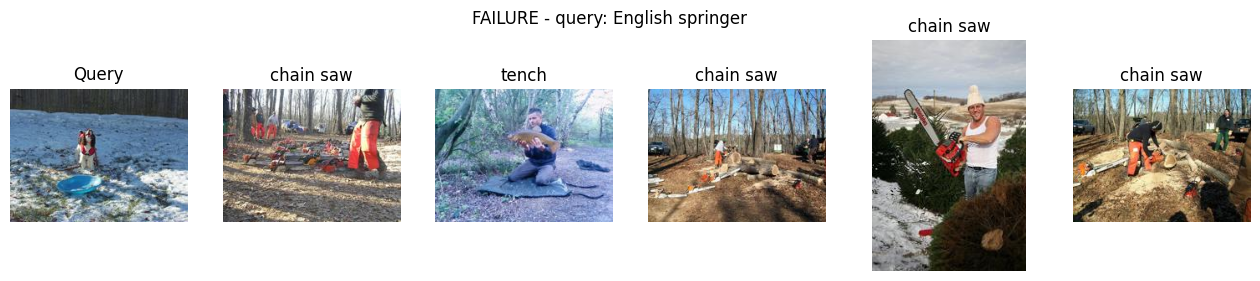

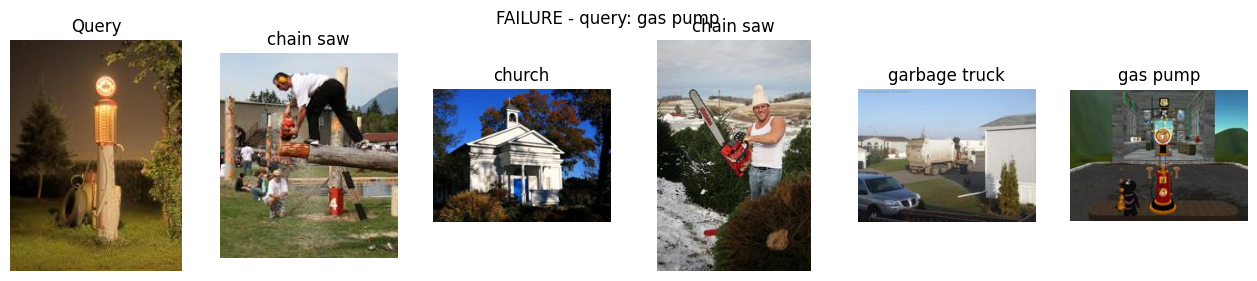

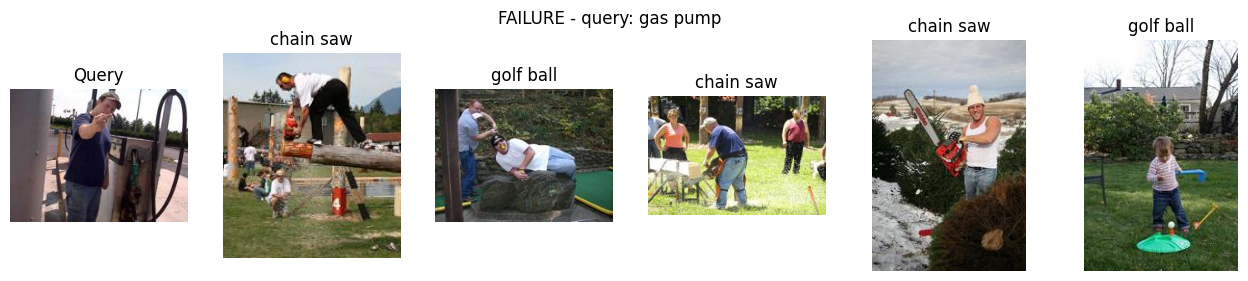

In [79]:
# Find and show failure cases
shown = 0
for qpath, qlabel in query_imgs:
    order = rank_cnn(qpath)
    if db_labels[order[0]] != qlabel:
        show_results(qpath, order[:5], f"FAILURE - query: {class_names[qlabel]}")
        shown += 1
    if shown==3:
        break

Failure cases:

The examples above show queries whose top retrieved images come from the wrong class. One common reason is similar backgrounds: the CNN encodes the whole image, so different objects against similar surroundings such as sky and grass can end up close together in feature space. Another reason is that low-level visual similarity can override semantic similarity, so two classes that share colour, texture, or shape can be ranked close despite being different objects. Failures also happen for images where the object is small, off-centre, or partially occluded, so the feature vector is dominated by the background.

Techniques to improve the retrieval system:

To improve robustness, instead of relying on the ImageNet VGG features, we could train a representation learning model with a contrastive objective and data augmentation, so that similar images are pushed to have similar encodings while different images are pushed apart, which tailors the features for retrieval. A stronger encoder such as a Vision Transformer would also capture semantics better than VGG.

To improve efficiency, an inverted index and a vector database could be used which would let the query be compared only against indexed or shared-feature images rather than every image by brute force, which would keep search fast as the database grows.

## Acknowledgements

- [Imagenette](https://github.com/fastai/imagenette) ([TensorFlow Datasets catalog entry](https://www.tensorflow.org/datasets/catalog/imagenette))
- [SIFT interest point detector (GeeksforGeeks)](https://www.geeksforgeeks.org/sift-interest-point-detector-using-python-opencv/)
- [VGG16 (torchvision docs)](https://docs.pytorch.org/vision/stable/models/vgg.html)
- The inverted-index pattern here is reused from my `recipe-search-engine` project